In [1]:
from pathlib import Path
import json
import math
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore", category=RuntimeWarning)
EXPECTED_EVALUATION_EPISODES = 100
MIN_TRAINING_EPISODES = 10000
PERSISTENT_EPSILON = 0.1
METHOD_NAMES = {
    "HalfCheetahCombinedMaxCost": "Scalar combined",
    "HalfCheetahMultiConstraintCost": "Two constraints",
}
METHOD_COLORS = {
    "Scalar combined": "#2F6BFF",
    "Two constraints": "#F28E2B",
}
root_candidates = [Path.cwd(), Path.cwd().parent]
REPO_ROOT = next((path.resolve() for path in root_candidates if (path / "data_train").exists()), Path.cwd().resolve())
EVALUATION_ROOT = REPO_ROOT / "analysis" / "outputs" / "best_rcac_extended_evaluation"
requested_directory = os.environ.get("BEST_RCAC_EVALUATION_DIRECTORY", "").strip()

def load_evaluation_metadata(path):
    metadata_path = path / "evaluation_metadata.json"
    if not metadata_path.exists():
        return None
    try:
        with metadata_path.open("r", encoding="utf-8") as handle:
            return json.load(handle)
    except Exception:
        return None

if requested_directory:
    EVALUATION_DIRECTORY = Path(requested_directory).expanduser().resolve()
else:
    evaluation_candidates = sorted(
        [path for path in EVALUATION_ROOT.glob("evaluation_*") if path.is_dir()],
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )
    matching_candidates = []
    for path in evaluation_candidates:
        candidate_metadata = load_evaluation_metadata(path)
        if candidate_metadata is None:
            continue
        if int(candidate_metadata.get("episodes_per_policy", 0)) != EXPECTED_EVALUATION_EPISODES:
            continue
        if int(candidate_metadata.get("minimum_training_episodes", 0)) < MIN_TRAINING_EPISODES:
            continue
        matching_candidates.append(path)
    if not matching_candidates:
        raise FileNotFoundError("No completed 100-episode evaluation of a 10,000-episode training run was found")
    EVALUATION_DIRECTORY = matching_candidates[0]

EVALUATION_METADATA = load_evaluation_metadata(EVALUATION_DIRECTORY)
if EVALUATION_METADATA is None:
    raise FileNotFoundError(f"Missing or unreadable evaluation metadata in {EVALUATION_DIRECTORY}")
if int(EVALUATION_METADATA.get("episodes_per_policy", 0)) != EXPECTED_EVALUATION_EPISODES:
    raise ValueError("The selected evaluation did not use exactly 100 episodes per policy")
FIGURE_ROOT = EVALUATION_DIRECTORY / "figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Evaluation directory: {EVALUATION_DIRECTORY}")
print(f"Figure directory: {FIGURE_ROOT}")


Evaluation directory: /home/bannanakid/RCRL_on_RCMDP/analysis/outputs/best_rcac_extended_evaluation/evaluation_20260824_130434
Figure directory: /home/bannanakid/RCRL_on_RCMDP/analysis/outputs/best_rcac_extended_evaluation/evaluation_20260824_130434/figures


In [2]:
episode_path = EVALUATION_DIRECTORY / "episode_metrics.csv"
policy_path = EVALUATION_DIRECTORY / "policy_summary.csv"
if not episode_path.exists() or not policy_path.exists():
    raise FileNotFoundError("episode_metrics.csv and policy_summary.csv are required")
episode_df = pd.read_csv(episode_path)
policy_df = pd.read_csv(policy_path)
required_episode_columns = {
    "policy_id", "environment", "run", "training_seed",
    "training_episodes", "checkpoint", "checkpoint_step",
    "episode", "evaluation_seed", "reward", "feasible",
    "combined_total_cost", "combined_max_cost",
    "pitch_total_cost", "pitch_max_cost",
    "joint_speed_total_cost", "joint_speed_max_cost",
    "pitch_violation", "joint_speed_violation",
}
missing_columns = sorted(required_episode_columns - set(episode_df.columns))
if missing_columns:
    raise ValueError(f"The evaluator output is missing columns: {missing_columns}")
for column in ["feasible", "pitch_violation", "joint_speed_violation"]:
    if episode_df[column].dtype != bool:
        episode_df[column] = episode_df[column].astype(str).str.lower().eq("true")
policy_df = policy_df[
    policy_df["environment"].isin(METHOD_NAMES)
    & (policy_df["training_episodes"] >= MIN_TRAINING_EPISODES)
].copy()
if policy_df.empty:
    raise ValueError("No scalar-combined or two-constraint 10,000-episode policies were found")
selected_policy_ids = []
for (_, run, training_seed), group in policy_df.groupby(["environment", "run", "training_seed"], dropna=False):
    environment = group["environment"].iloc[0]
    if environment == "HalfCheetahMultiConstraintCost":
        numbered = group[pd.to_numeric(group["checkpoint_step"], errors="coerce").notna()].copy()
        numbered["checkpoint_step_numeric"] = pd.to_numeric(numbered["checkpoint_step"], errors="coerce")
        numbered = numbered[numbered["checkpoint_step_numeric"] > 0]
        chosen = numbered.sort_values("checkpoint_step_numeric").iloc[-1] if not numbered.empty else group.iloc[-1]
    else:
        best_rows = group[group["checkpoint"] == "best"]
        chosen = best_rows.iloc[-1] if not best_rows.empty else group.iloc[-1]
    selected_policy_ids.append(chosen["policy_id"])
selected_policy_df = policy_df[policy_df["policy_id"].isin(selected_policy_ids)].copy()
episode_df = episode_df[episode_df["policy_id"].isin(selected_policy_ids)].copy()
episode_df["method"] = episode_df["environment"].map(METHOD_NAMES)
episode_df["label"] = episode_df.apply(lambda row: f"{row['method']}, seed {int(row['training_seed'])}", axis=1)
selected_policy_df["method"] = selected_policy_df["environment"].map(METHOD_NAMES)
selected_policy_df["label"] = selected_policy_df.apply(lambda row: f"{row['method']}, seed {int(row['training_seed'])}", axis=1)
policy_order_df = selected_policy_df.assign(
    method_order=selected_policy_df["method"].map({"Scalar combined": 0, "Two constraints": 1})
).sort_values(["training_seed", "method_order", "run"])
POLICY_ORDER = policy_order_df["policy_id"].tolist()
LABEL_ORDER = policy_order_df["label"].tolist()
METHOD_ORDER = policy_order_df["method"].tolist()
TRAINING_SEEDS = sorted(int(seed) for seed in selected_policy_df["training_seed"].dropna().unique())
marker_cycle = ["o", "s", "^", "D", "P", "X", "v", "<", ">", "*", "h", "8"]
linestyle_cycle = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1)), (0, (5, 2, 1, 2)), (0, (2, 2)), (0, (4, 1, 1, 1, 1, 1)), (0, (3, 2)), (0, (6, 2))]
hatch_cycle = ["//", "\\", "xx", "..", "oo", "++", "**", "--", "||", "OO", "\\//", "xx.."]
SEED_MARKERS = {seed: marker_cycle[index % len(marker_cycle)] for index, seed in enumerate(TRAINING_SEEDS)}
SEED_LINESTYLES = {seed: linestyle_cycle[index % len(linestyle_cycle)] for index, seed in enumerate(TRAINING_SEEDS)}
SEED_HATCHES = {seed: hatch_cycle[index % len(hatch_cycle)] for index, seed in enumerate(TRAINING_SEEDS)}
METHOD_COLOR_HANDLES = [Patch(facecolor=METHOD_COLORS[method], edgecolor="black", alpha=0.82, label=method) for method in METHOD_COLORS]
METHOD_LINE_HANDLES = [Line2D([0], [0], color=METHOD_COLORS[method], linewidth=2.5, label=method) for method in METHOD_COLORS]
METHOD_EDGE_HANDLES = [Line2D([0], [0], color=METHOD_COLORS[method], linewidth=3.0, label=method) for method in METHOD_COLORS]
SEED_HATCH_HANDLES = [Patch(facecolor="white", edgecolor="black", hatch=SEED_HATCHES[seed], label=f"Seed {seed}") for seed in TRAINING_SEEDS]
SEED_LINE_HANDLES = [Line2D([0], [0], color="#444444", marker=SEED_MARKERS[seed], linestyle=SEED_LINESTYLES[seed], markersize=7, linewidth=1.8, label=f"Seed {seed}") for seed in TRAINING_SEEDS]
SEED_MARKER_HANDLES = [Line2D([0], [0], color="#444444", marker=SEED_MARKERS[seed], linestyle="none", markersize=8, label=f"Seed {seed}") for seed in TRAINING_SEEDS]

def style_policy_bars(container, seeds, methods, edge_by_method=False):
    for bar, seed, method in zip(container.patches, seeds, methods):
        bar.set_hatch(SEED_HATCHES[int(seed)])
        bar.set_edgecolor(METHOD_COLORS[method] if edge_by_method else "black")
        bar.set_linewidth(1.6 if edge_by_method else 0.7)

episode_counts = episode_df.groupby("policy_id")["episode"].nunique().reindex(POLICY_ORDER)
if not np.all(episode_counts.to_numpy() == EXPECTED_EVALUATION_EPISODES):
    raise ValueError(f"Every selected policy must contain 100 unique episodes: {episode_counts.to_dict()}")
if episode_df[["pitch_max_cost", "joint_speed_max_cost", "combined_max_cost"]].isna().any().any():
    raise ValueError("Individual or combined costs are missing from the evaluator output")
print(f"Selected policies: {len(POLICY_ORDER)}")
print(f"Evaluation episodes: {len(episode_df)}")
for policy_id in POLICY_ORDER:
    policy_rows = episode_df[episode_df["policy_id"] == policy_id]
    print(f"{policy_rows['label'].iloc[0]}: checkpoint {policy_rows['checkpoint'].iloc[0]}, {len(policy_rows)} episodes")


Selected policies: 12
Evaluation episodes: 1200
Scalar combined, seed 5: checkpoint best, 100 episodes
Two constraints, seed 5: checkpoint step_9400, 100 episodes
Scalar combined, seed 11: checkpoint best, 100 episodes
Two constraints, seed 11: checkpoint step_6900, 100 episodes
Scalar combined, seed 17: checkpoint best, 100 episodes
Two constraints, seed 17: checkpoint step_9900, 100 episodes
Scalar combined, seed 23: checkpoint best, 100 episodes
Two constraints, seed 23: checkpoint step_3900, 100 episodes
Scalar combined, seed 29: checkpoint best, 100 episodes
Two constraints, seed 29: checkpoint step_3700, 100 episodes
Scalar combined, seed 37: checkpoint best, 100 episodes
Two constraints, seed 37: checkpoint step_4600, 100 episodes


In [3]:
def mean_ci95(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    mean = float(np.mean(values))
    sem = float(np.std(values, ddof=1) / np.sqrt(len(values))) if len(values) > 1 else 0.0
    return mean, mean - 1.96 * sem, mean + 1.96 * sem

def wilson_ci95(successes, observations):
    if observations == 0:
        return np.nan, np.nan
    z = 1.96
    proportion = successes / observations
    denominator = 1.0 + z * z / observations
    center = (proportion + z * z / (2.0 * observations)) / denominator
    margin = z * np.sqrt(proportion * (1.0 - proportion) / observations + z * z / (4.0 * observations * observations)) / denominator
    return float(center - margin), float(center + margin)

summary_records = []
metrics = [
    "reward", "combined_total_cost", "combined_max_cost",
    "pitch_total_cost", "pitch_max_cost",
    "joint_speed_total_cost", "joint_speed_max_cost",
]
for policy_id in POLICY_ORDER:
    rows = episode_df[episode_df["policy_id"] == policy_id].sort_values("episode")
    record = {
        "policy_id": policy_id,
        "method": rows["method"].iloc[0],
        "label": rows["label"].iloc[0],
        "run": int(rows["run"].iloc[0]),
        "training_seed": int(rows["training_seed"].iloc[0]),
        "checkpoint": rows["checkpoint"].iloc[0],
        "evaluation_episodes": len(rows),
    }
    for metric in metrics:
        mean, low, high = mean_ci95(rows[metric])
        record[f"{metric}_mean"] = mean
        record[f"{metric}_ci95_low"] = low
        record[f"{metric}_ci95_high"] = high
        record[f"{metric}_observed_maximum"] = float(rows[metric].max())
    feasible_count = int(rows["feasible"].sum())
    feasible_low, feasible_high = wilson_ci95(feasible_count, len(rows))
    record["feasible_count"] = feasible_count
    record["feasible_fraction"] = feasible_count / len(rows)
    record["feasible_ci95_low"] = feasible_low
    record["feasible_ci95_high"] = feasible_high
    record["pitch_violation_fraction"] = float(rows["pitch_violation"].mean())
    record["joint_speed_violation_fraction"] = float(rows["joint_speed_violation"].mean())
    summary_records.append(record)
summary_df = pd.DataFrame(summary_records)
summary_df.to_csv(FIGURE_ROOT / "graph_summary.csv", index=False)
print("Error bars summarize variation across the 100 deterministic evaluation episodes for each trained policy.")


Error bars summarize variation across the 100 deterministic evaluation episodes for each trained policy.


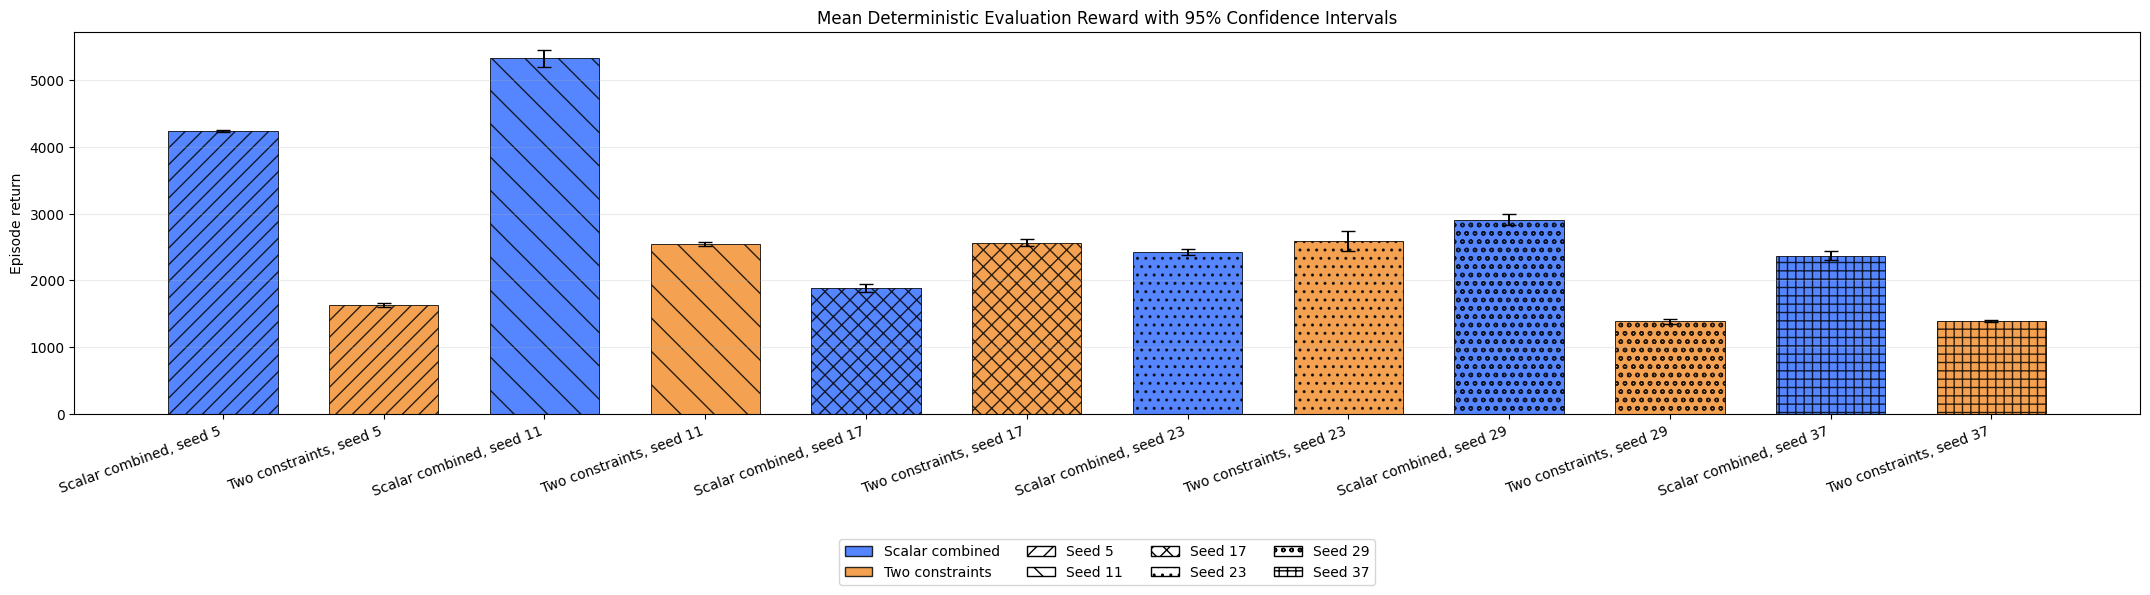

In [4]:
x = np.arange(len(summary_df))
means = summary_df["reward_mean"].to_numpy()
lower = np.maximum(means - summary_df["reward_ci95_low"].to_numpy(), 0.0)
upper = np.maximum(summary_df["reward_ci95_high"].to_numpy() - means, 0.0)
colors = [METHOD_COLORS[method] for method in summary_df["method"]]
figure, axis = plt.subplots(figsize=(max(8, len(x) * 1.8), 6.4))
bars = axis.bar(x, means, color=colors, alpha=0.82, width=0.68)
style_policy_bars(bars, summary_df["training_seed"], summary_df["method"])
axis.errorbar(x, means, yerr=np.vstack([lower, upper]), fmt="none", ecolor="black", capsize=5, linewidth=1.4)
axis.set_xticks(x, summary_df["label"], rotation=20, ha="right")
axis.set_ylabel("Episode return")
axis.set_title("Mean Deterministic Evaluation Reward with 95% Confidence Intervals")
axis.grid(axis="y", alpha=0.25)
axis.legend(handles=METHOD_COLOR_HANDLES + SEED_HATCH_HANDLES, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.31))
figure.tight_layout()
figure.savefig(FIGURE_ROOT / "reward_mean_ci95.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(figure)


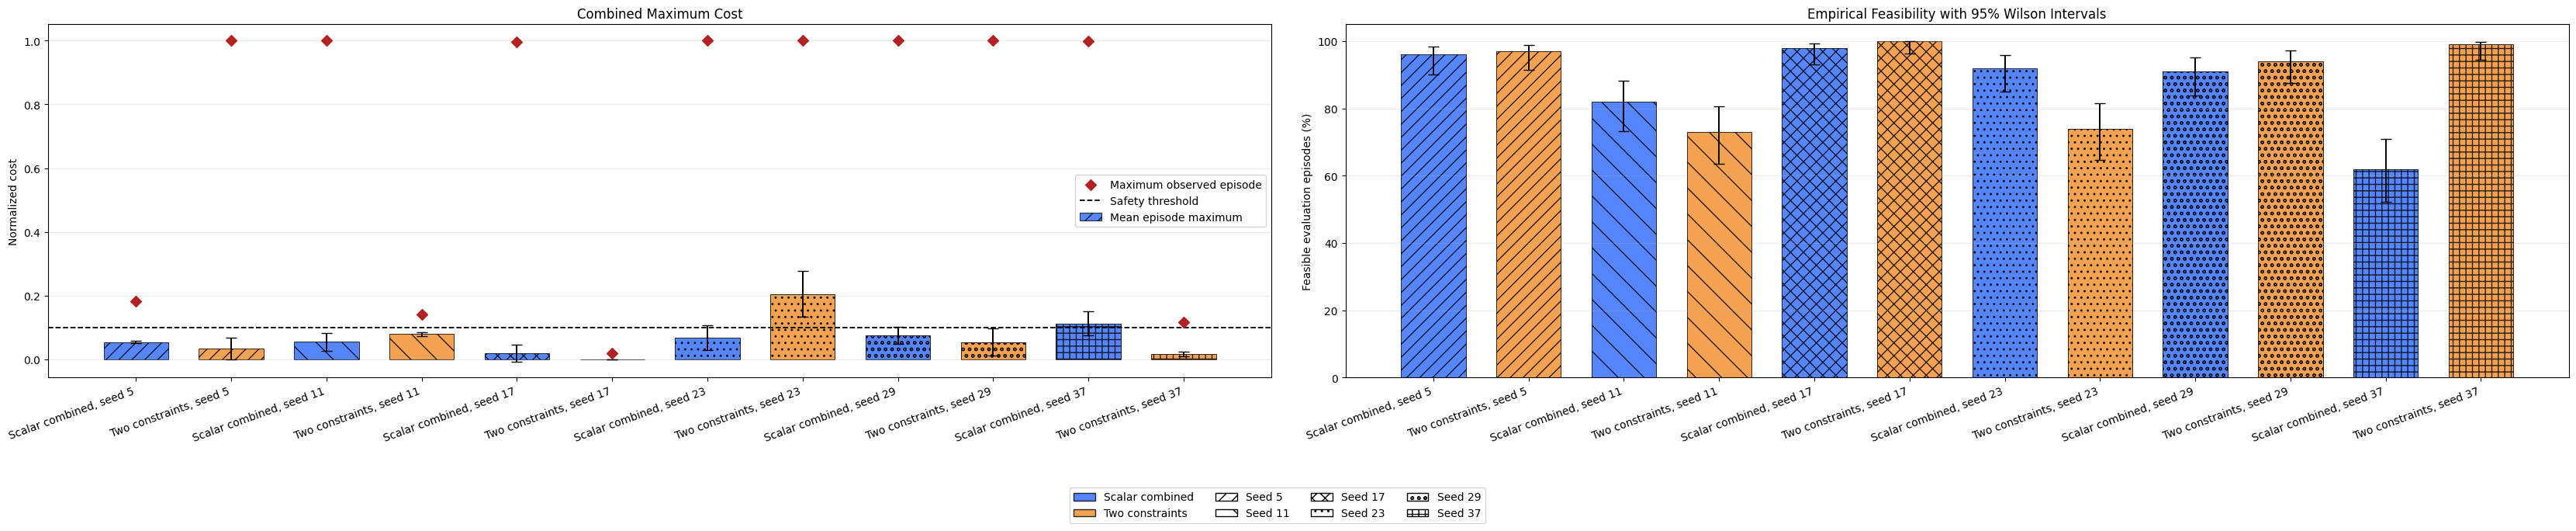

In [5]:
x = np.arange(len(summary_df))
colors = [METHOD_COLORS[method] for method in summary_df["method"]]
figure, axes = plt.subplots(1, 2, figsize=(max(13, len(x) * 2.8), 6.8))
combined_means = summary_df["combined_max_cost_mean"].to_numpy()
combined_lower = np.maximum(combined_means - summary_df["combined_max_cost_ci95_low"].to_numpy(), 0.0)
combined_upper = np.maximum(summary_df["combined_max_cost_ci95_high"].to_numpy() - combined_means, 0.0)
combined_bars = axes[0].bar(x, combined_means, color=colors, alpha=0.82, width=0.68, label="Mean episode maximum")
style_policy_bars(combined_bars, summary_df["training_seed"], summary_df["method"])
axes[0].errorbar(x, combined_means, yerr=np.vstack([combined_lower, combined_upper]), fmt="none", ecolor="black", capsize=5, linewidth=1.4)
axes[0].scatter(x, summary_df["combined_max_cost_observed_maximum"], marker="D", color="#B22222", s=50, label="Maximum observed episode", zorder=4)
axes[0].axhline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.3, label="Safety threshold")
axes[0].set_xticks(x, summary_df["label"], rotation=20, ha="right")
axes[0].set_ylabel("Normalized cost")
axes[0].set_title("Combined Maximum Cost")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend()
fractions = summary_df["feasible_fraction"].to_numpy()
fraction_lower = np.maximum(fractions - summary_df["feasible_ci95_low"].to_numpy(), 0.0)
fraction_upper = np.maximum(summary_df["feasible_ci95_high"].to_numpy() - fractions, 0.0)
feasibility_bars = axes[1].bar(x, 100.0 * fractions, color=colors, alpha=0.82, width=0.68)
style_policy_bars(feasibility_bars, summary_df["training_seed"], summary_df["method"])
axes[1].errorbar(x, 100.0 * fractions, yerr=100.0 * np.vstack([fraction_lower, fraction_upper]), fmt="none", ecolor="black", capsize=5, linewidth=1.4)
axes[1].set_xticks(x, summary_df["label"], rotation=20, ha="right")
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Feasible evaluation episodes (%)")
axes[1].set_title("Empirical Feasibility with 95% Wilson Intervals")
axes[1].grid(axis="y", alpha=0.25)
figure.legend(handles=METHOD_COLOR_HANDLES + SEED_HATCH_HANDLES, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.01))
figure.tight_layout(rect=[0, 0.13, 1, 1])
figure.savefig(FIGURE_ROOT / "combined_cost_and_feasibility.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(figure)


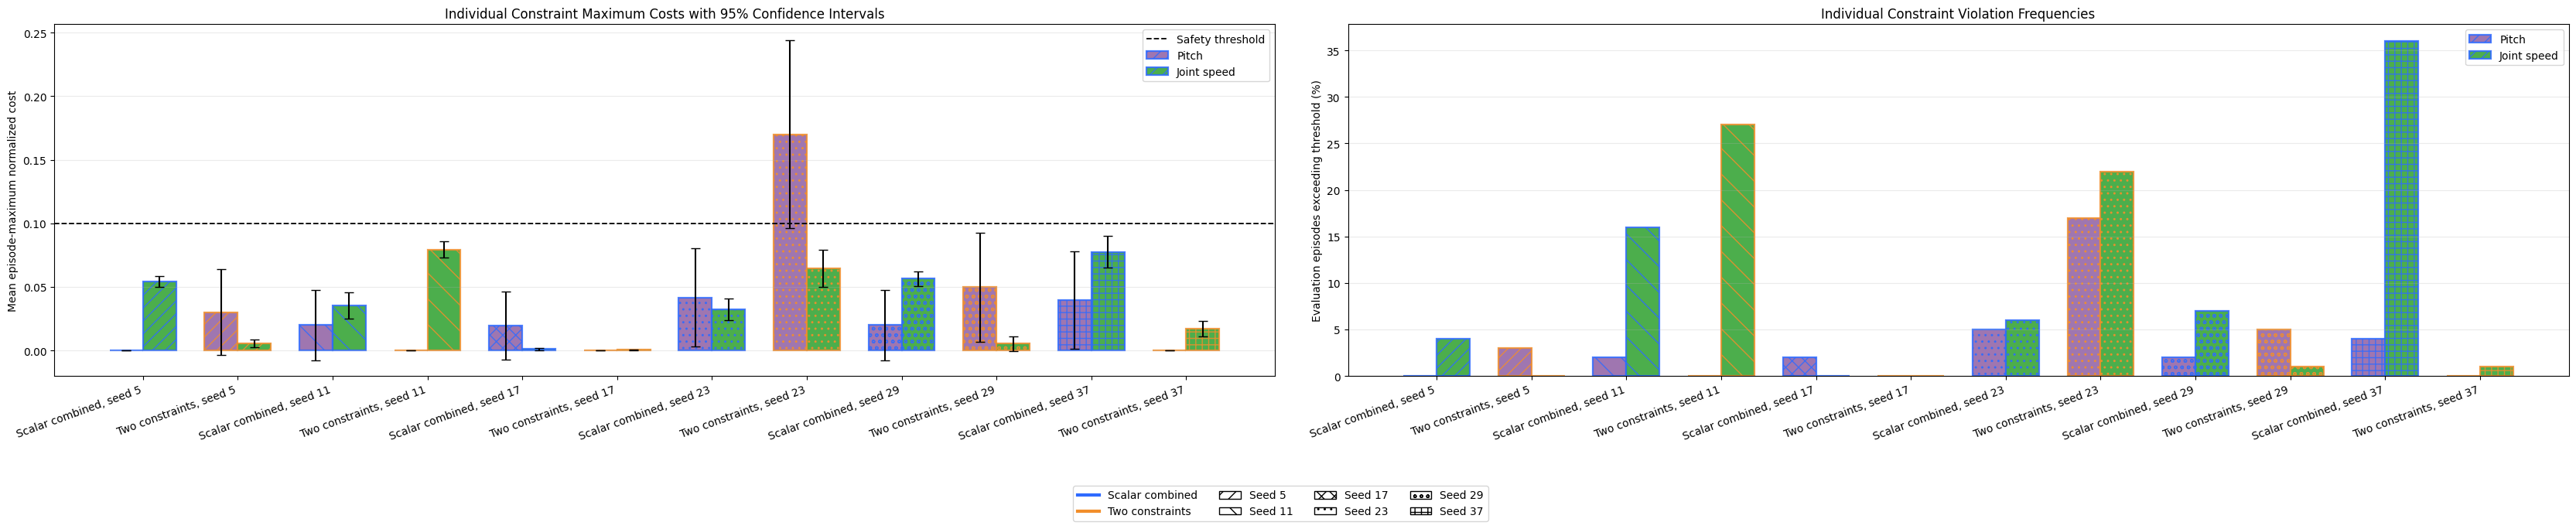

In [6]:
x = np.arange(len(summary_df))
width = 0.35
pitch_means = summary_df["pitch_max_cost_mean"].to_numpy()
joint_means = summary_df["joint_speed_max_cost_mean"].to_numpy()
pitch_errors = np.vstack([
    np.maximum(pitch_means - summary_df["pitch_max_cost_ci95_low"].to_numpy(), 0.0),
    np.maximum(summary_df["pitch_max_cost_ci95_high"].to_numpy() - pitch_means, 0.0),
])
joint_errors = np.vstack([
    np.maximum(joint_means - summary_df["joint_speed_max_cost_ci95_low"].to_numpy(), 0.0),
    np.maximum(summary_df["joint_speed_max_cost_ci95_high"].to_numpy() - joint_means, 0.0),
])
figure, axes = plt.subplots(1, 2, figsize=(max(13, len(x) * 2.8), 6.8))
pitch_bars = axes[0].bar(x - width / 2, pitch_means, width, yerr=pitch_errors, capsize=4, color="#8E5EA2", alpha=0.85, label="Pitch")
joint_bars = axes[0].bar(x + width / 2, joint_means, width, yerr=joint_errors, capsize=4, color="#2CA02C", alpha=0.85, label="Joint speed")
style_policy_bars(pitch_bars, summary_df["training_seed"], summary_df["method"], edge_by_method=True)
style_policy_bars(joint_bars, summary_df["training_seed"], summary_df["method"], edge_by_method=True)
axes[0].axhline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.3, label="Safety threshold")
axes[0].set_xticks(x, summary_df["label"], rotation=20, ha="right")
axes[0].set_ylabel("Mean episode-maximum normalized cost")
axes[0].set_title("Individual Constraint Maximum Costs with 95% Confidence Intervals")
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend()
pitch_violation_bars = axes[1].bar(x - width / 2, 100.0 * summary_df["pitch_violation_fraction"], width, color="#8E5EA2", alpha=0.85, label="Pitch")
joint_violation_bars = axes[1].bar(x + width / 2, 100.0 * summary_df["joint_speed_violation_fraction"], width, color="#2CA02C", alpha=0.85, label="Joint speed")
style_policy_bars(pitch_violation_bars, summary_df["training_seed"], summary_df["method"], edge_by_method=True)
style_policy_bars(joint_violation_bars, summary_df["training_seed"], summary_df["method"], edge_by_method=True)
axes[1].set_xticks(x, summary_df["label"], rotation=20, ha="right")
axes[1].set_ylim(bottom=0)
axes[1].set_ylabel("Evaluation episodes exceeding threshold (%)")
axes[1].set_title("Individual Constraint Violation Frequencies")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend()
figure.legend(handles=METHOD_EDGE_HANDLES + SEED_HATCH_HANDLES, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.01))
figure.tight_layout(rect=[0, 0.13, 1, 1])
figure.savefig(FIGURE_ROOT / "individual_max_costs_and_violations.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(figure)


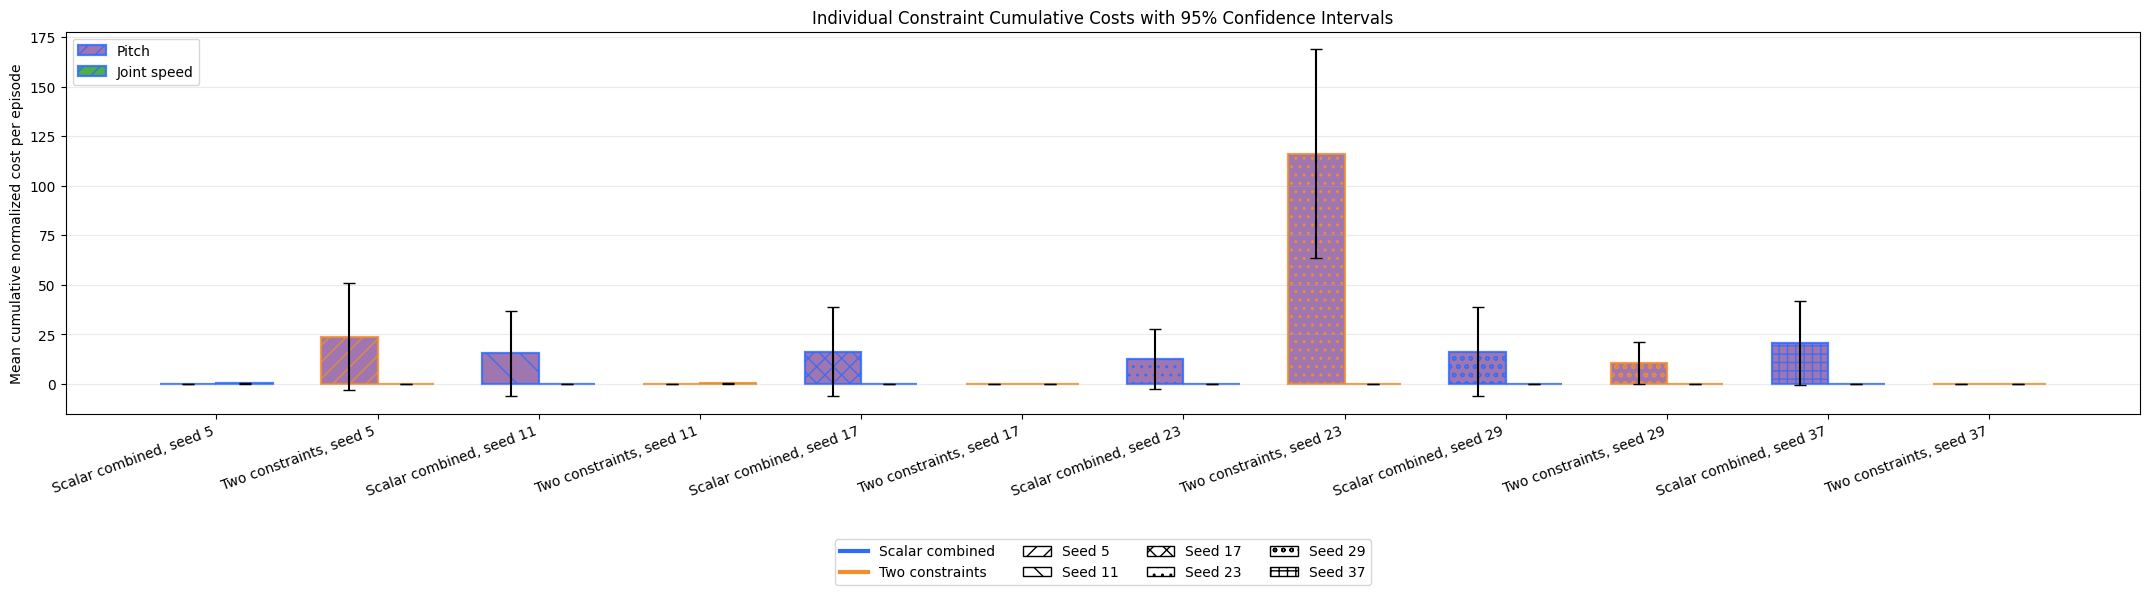

In [7]:
x = np.arange(len(summary_df))
width = 0.35
pitch_means = summary_df["pitch_total_cost_mean"].to_numpy()
joint_means = summary_df["joint_speed_total_cost_mean"].to_numpy()
pitch_errors = np.vstack([
    np.maximum(pitch_means - summary_df["pitch_total_cost_ci95_low"].to_numpy(), 0.0),
    np.maximum(summary_df["pitch_total_cost_ci95_high"].to_numpy() - pitch_means, 0.0),
])
joint_errors = np.vstack([
    np.maximum(joint_means - summary_df["joint_speed_total_cost_ci95_low"].to_numpy(), 0.0),
    np.maximum(summary_df["joint_speed_total_cost_ci95_high"].to_numpy() - joint_means, 0.0),
])
figure, axis = plt.subplots(figsize=(max(8, len(x) * 1.8), 6.4))
pitch_bars = axis.bar(x - width / 2, pitch_means, width, yerr=pitch_errors, capsize=4, color="#8E5EA2", alpha=0.85, label="Pitch")
joint_bars = axis.bar(x + width / 2, joint_means, width, yerr=joint_errors, capsize=4, color="#2CA02C", alpha=0.85, label="Joint speed")
style_policy_bars(pitch_bars, summary_df["training_seed"], summary_df["method"], edge_by_method=True)
style_policy_bars(joint_bars, summary_df["training_seed"], summary_df["method"], edge_by_method=True)
axis.set_xticks(x, summary_df["label"], rotation=20, ha="right")
axis.set_ylabel("Mean cumulative normalized cost per episode")
axis.set_title("Individual Constraint Cumulative Costs with 95% Confidence Intervals")
axis.grid(axis="y", alpha=0.25)
constraint_legend = axis.legend(loc="upper left")
axis.add_artist(constraint_legend)
axis.legend(handles=METHOD_EDGE_HANDLES + SEED_HATCH_HANDLES, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.31))
figure.tight_layout()
figure.savefig(FIGURE_ROOT / "individual_total_costs_mean_ci95.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(figure)


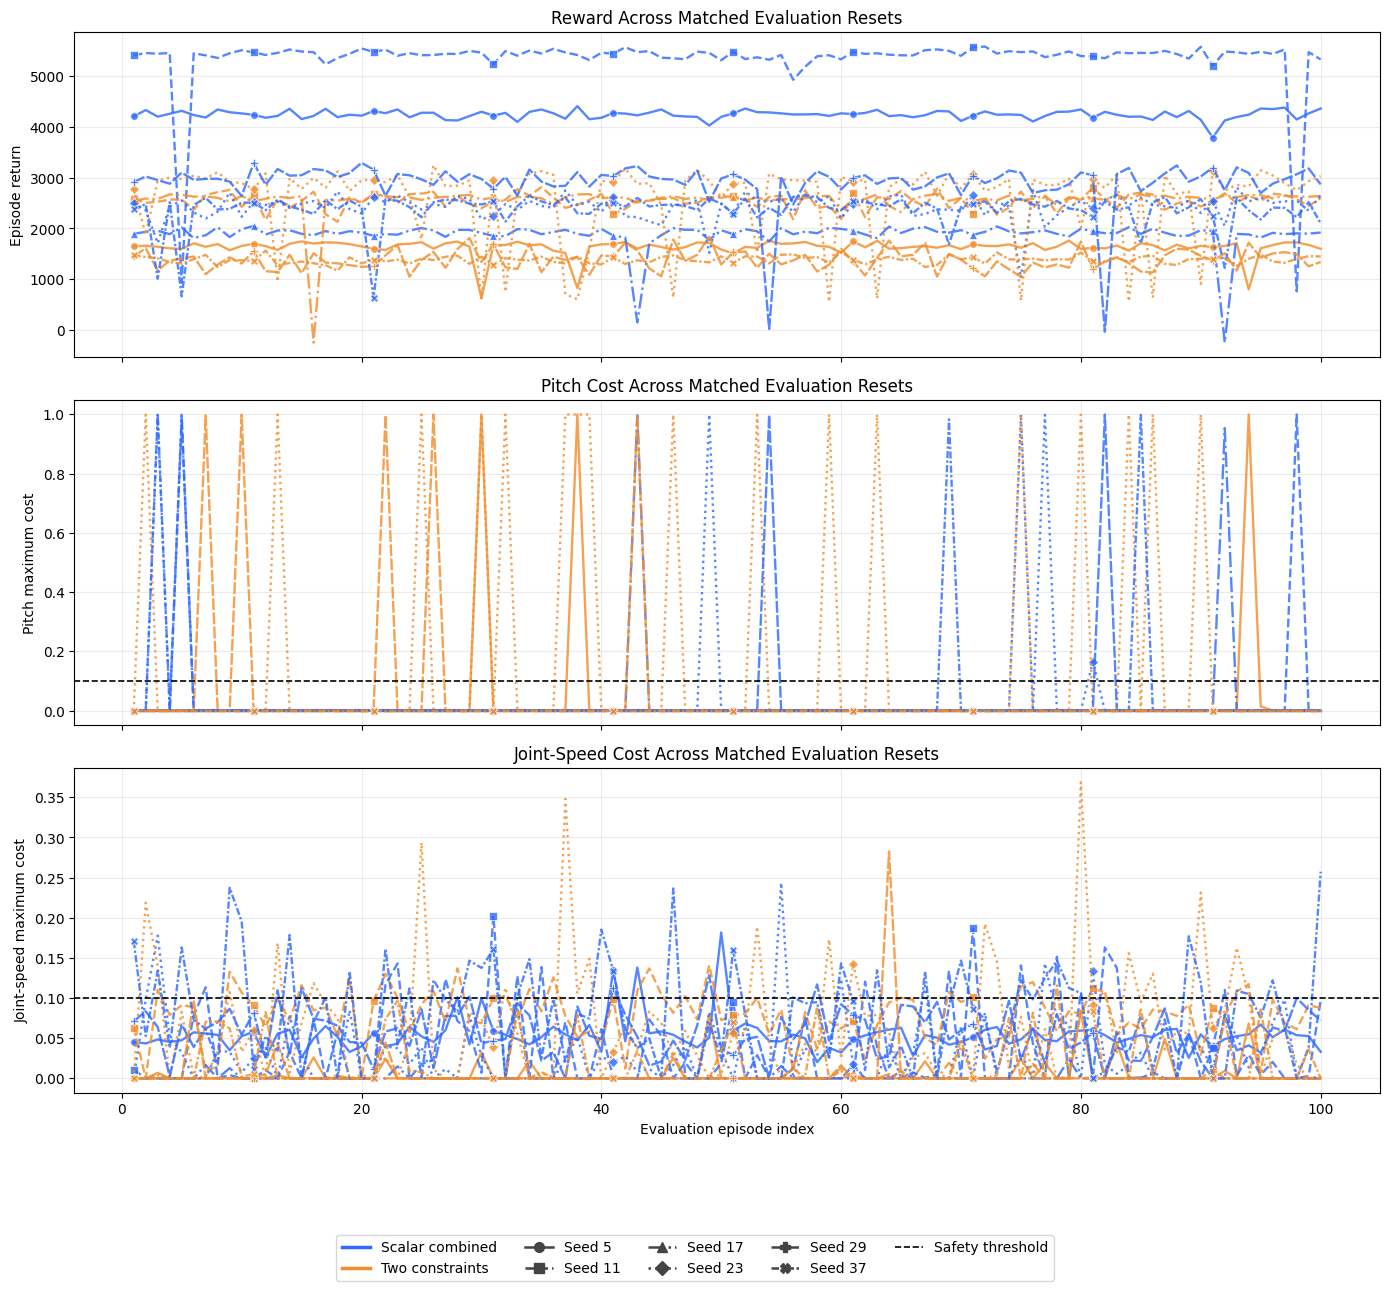

In [8]:
figure, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)
for policy_id in POLICY_ORDER:
    rows = episode_df[episode_df["policy_id"] == policy_id].sort_values("episode")
    method = rows["method"].iloc[0]
    seed = int(rows["training_seed"].iloc[0])
    style = {
        "color": METHOD_COLORS[method],
        "marker": SEED_MARKERS[seed],
        "linestyle": SEED_LINESTYLES[seed],
        "markevery": 10,
        "markersize": 5.5,
        "markeredgecolor": "white",
        "markeredgewidth": 0.6,
        "alpha": 0.82,
        "linewidth": 1.7,
    }
    axes[0].plot(rows["episode"], rows["reward"], **style)
    axes[1].plot(rows["episode"], rows["pitch_max_cost"], **style)
    axes[2].plot(rows["episode"], rows["joint_speed_max_cost"], **style)
axes[0].set_ylabel("Episode return")
axes[0].set_title("Reward Across Matched Evaluation Resets")
axes[1].axhline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.2)
axes[1].set_ylabel("Pitch maximum cost")
axes[1].set_title("Pitch Cost Across Matched Evaluation Resets")
axes[2].axhline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.2)
axes[2].set_ylabel("Joint-speed maximum cost")
axes[2].set_xlabel("Evaluation episode index")
axes[2].set_title("Joint-Speed Cost Across Matched Evaluation Resets")
for axis in axes:
    axis.grid(alpha=0.25)
threshold_handle = Line2D([0], [0], color="black", linestyle="--", linewidth=1.2, label="Safety threshold")
figure.legend(handles=METHOD_LINE_HANDLES + SEED_LINE_HANDLES + [threshold_handle], ncol=5, loc="lower center", bbox_to_anchor=(0.5, 0.005))
figure.tight_layout(rect=[0, 0.11, 1, 1])
figure.savefig(FIGURE_ROOT / "episode_reward_and_individual_costs.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(figure)


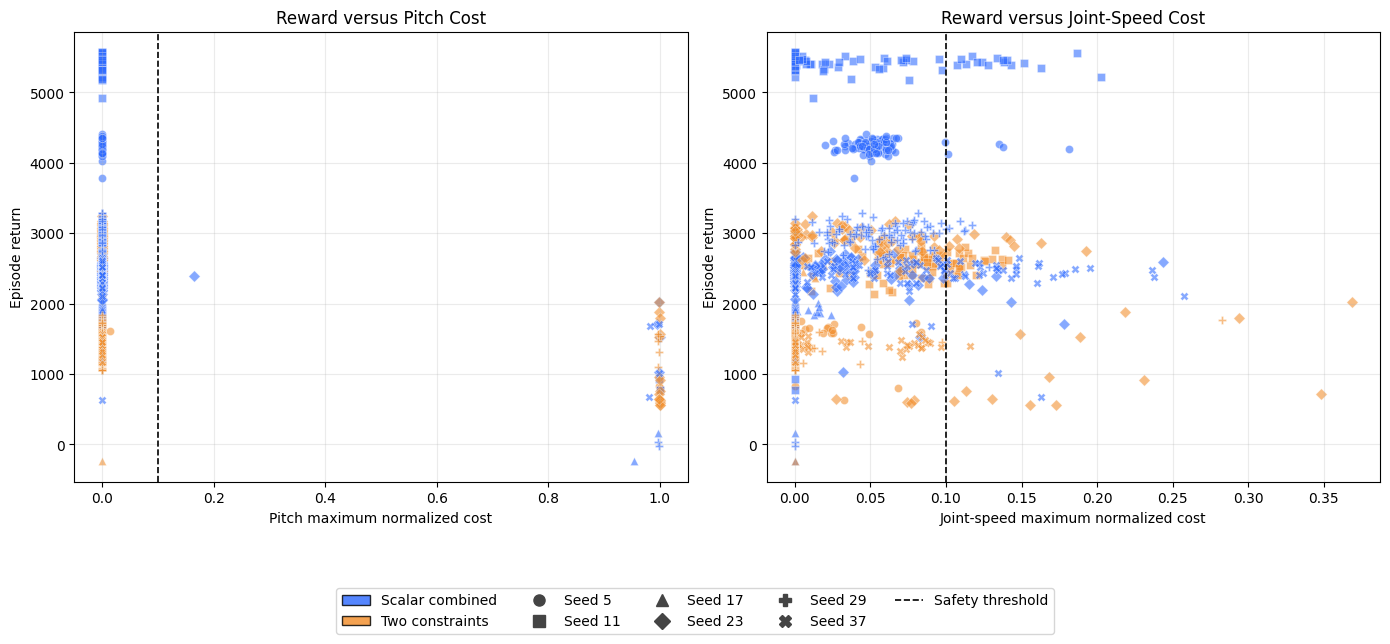

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for policy_id in POLICY_ORDER:
    rows = episode_df[episode_df["policy_id"] == policy_id]
    method = rows["method"].iloc[0]
    seed = int(rows["training_seed"].iloc[0])
    axes[0].scatter(rows["pitch_max_cost"], rows["reward"], color=METHOD_COLORS[method], marker=SEED_MARKERS[seed], alpha=0.58, s=34, edgecolors="white", linewidths=0.4)
    axes[1].scatter(rows["joint_speed_max_cost"], rows["reward"], color=METHOD_COLORS[method], marker=SEED_MARKERS[seed], alpha=0.58, s=34, edgecolors="white", linewidths=0.4)
axes[0].axvline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.2)
axes[1].axvline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.2)
axes[0].set_xlabel("Pitch maximum normalized cost")
axes[1].set_xlabel("Joint-speed maximum normalized cost")
axes[0].set_ylabel("Episode return")
axes[1].set_ylabel("Episode return")
axes[0].set_title("Reward versus Pitch Cost")
axes[1].set_title("Reward versus Joint-Speed Cost")
for axis in axes:
    axis.grid(alpha=0.25)
threshold_handle = Line2D([0], [0], color="black", linestyle="--", linewidth=1.2, label="Safety threshold")
figure.legend(handles=METHOD_COLOR_HANDLES + SEED_MARKER_HANDLES + [threshold_handle], ncol=5, loc="lower center", bbox_to_anchor=(0.5, 0.005))
figure.tight_layout(rect=[0, 0.16, 1, 1])
figure.savefig(FIGURE_ROOT / "reward_vs_individual_costs.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(figure)


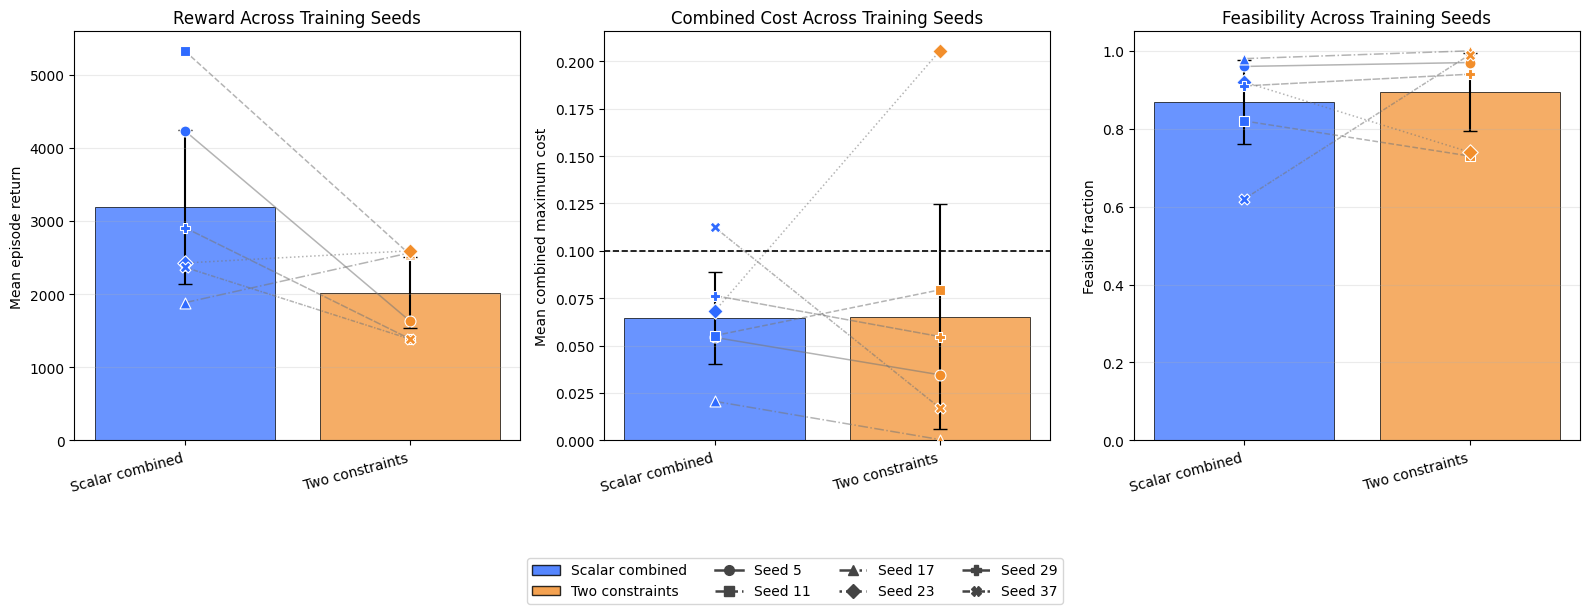

In [10]:
seed_policy_means = episode_df.groupby(["method", "training_seed", "policy_id"], as_index=False).agg(
    reward_mean=("reward", "mean"),
    combined_max_cost_mean=("combined_max_cost", "mean"),
    pitch_max_cost_mean=("pitch_max_cost", "mean"),
    joint_speed_max_cost_mean=("joint_speed_max_cost", "mean"),
    feasible_fraction=("feasible", "mean"),
)
seed_counts = seed_policy_means.groupby("method")["training_seed"].nunique()
if len(seed_counts) == 2 and seed_counts.min() >= 2:
    metrics_to_plot = ["reward_mean", "combined_max_cost_mean", "feasible_fraction"]
    ylabels = ["Mean episode return", "Mean combined maximum cost", "Feasible fraction"]
    titles = ["Reward Across Training Seeds", "Combined Cost Across Training Seeds", "Feasibility Across Training Seeds"]
    methods = ["Scalar combined", "Two constraints"]
    figure, axes = plt.subplots(1, 3, figsize=(16, 6.2))
    for axis, metric, ylabel, title in zip(axes, metrics_to_plot, ylabels, titles):
        means = []
        errors = []
        for method in methods:
            values = seed_policy_means.loc[seed_policy_means["method"] == method, metric].to_numpy()
            means.append(float(np.mean(values)))
            errors.append(float(1.96 * np.std(values, ddof=1) / np.sqrt(len(values))))
        method_bars = axis.bar(np.arange(2), means, yerr=errors, capsize=5, color=[METHOD_COLORS[method] for method in methods], alpha=0.72, zorder=1)
        for bar in method_bars.patches:
            bar.set_edgecolor("black")
            bar.set_linewidth(0.7)
        for seed in TRAINING_SEEDS:
            seed_rows = seed_policy_means[seed_policy_means["training_seed"] == seed]
            matched_positions = []
            matched_values = []
            matched_colors = []
            for method_index, method in enumerate(methods):
                values = seed_rows.loc[seed_rows["method"] == method, metric].to_numpy()
                if len(values) == 1:
                    matched_positions.append(method_index)
                    matched_values.append(float(values[0]))
                    matched_colors.append(METHOD_COLORS[method])
            if len(matched_positions) == 2:
                axis.plot(matched_positions, matched_values, color="#777777", linestyle=SEED_LINESTYLES[seed], linewidth=1.1, alpha=0.55, zorder=2)
            for position, value, color in zip(matched_positions, matched_values, matched_colors):
                axis.scatter(position, value, color=color, marker=SEED_MARKERS[seed], s=62, edgecolor="white", linewidth=0.8, zorder=3)
        axis.set_xticks(np.arange(2), methods, rotation=15, ha="right")
        axis.set_ylabel(ylabel)
        axis.set_title(title)
        axis.grid(axis="y", alpha=0.25)
    axes[1].axhline(PERSISTENT_EPSILON, color="black", linestyle="--", linewidth=1.2)
    axes[2].set_ylim(0, 1.05)
    figure.legend(handles=METHOD_COLOR_HANDLES + SEED_LINE_HANDLES, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.005))
    figure.tight_layout(rect=[0, 0.17, 1, 1])
    figure.savefig(FIGURE_ROOT / "algorithm_means_across_training_seeds.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(figure)
else:
    print("Across-training-seed confidence intervals require at least two completed training seeds per method.")
